Text(0.5, 1.0, 'Synthetic 2-dim dataset with two correlated Gaussian features')

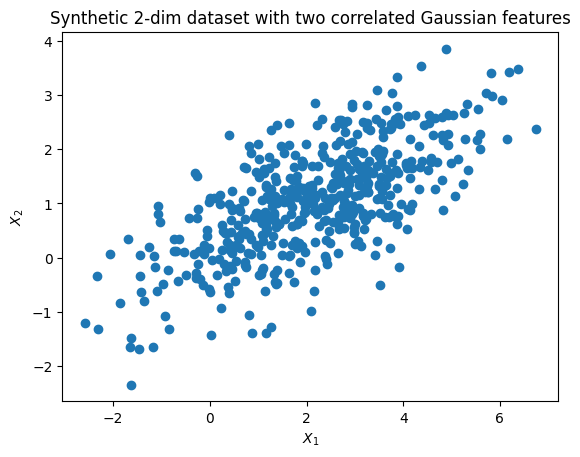

In [160]:
import numpy as np
import matplotlib.pyplot as plt

# P3 Q2: Describe the Gaussian generator and observed correlation.
def generate_data(n_samples=500, seed=0, mean=None, covariance=None):
    """Return reproducible Gaussian samples (n_samples,2) using NumPy and seed.

    Defaults: mean=[2,-1], covariance=[[3,1.2],[1.2,1]]. Custom mean has shape
    (2,), covariance (2,2) is positive definite. Do not mutate input arrays.
    """
    # YOUR CODE HERE
    np.random.seed(seed)
    return np.random.multivariate_normal(mean, covariance, size=n_samples)

# We use examples from the provided function.
n_samples = 500
mean = np.array([2, 1])
cov = np.array([[3,1.2],[1.2,1]])
X = generate_data(n_samples=n_samples, mean=mean, covariance=cov)
# Scatter plots
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel(r"$X_{1}$")
plt.ylabel(r"$X_{2}$")
plt.title("Synthetic 2-dim dataset with two correlated Gaussian features")

There appears to be a moderate to high positive correlation in the data, which makes sense given the covariance matrix uses covariance of 1.2 on the off diagonal.

Eigenvalues=[3.38290403 0.43871435], 
Eigenvectors (PC's)=[[ 0.42808187 -0.90373996]
 [-0.90373996 -0.42808187]]


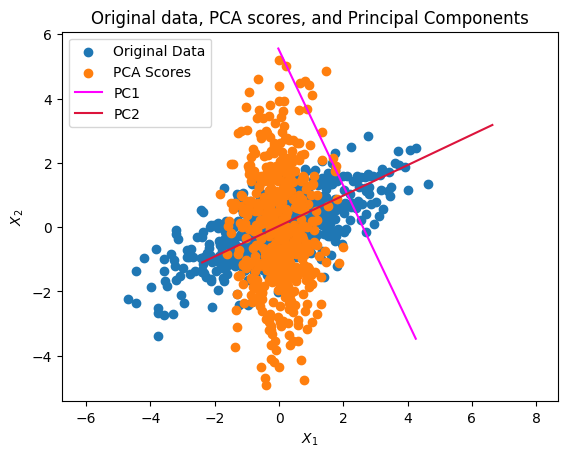

In [161]:
# P3 Q3: Link centering/covariance/eigendecomposition to the derivation and explain the plot.
def pca(X):
    """Fit NumPy PCA without mutating finite X of shape (n,2), n>=2.

    Return dict: mean (2,), centered (n,2), covariance (2,2), eigenvalues (2,),
    components (2,2), scores (n,2). Use covariance divisor n-1, descending
    eigenvalues, orthonormal eigenvectors as columns, scores=centered@components.
    Signs/tied-eigenspace bases are free. Include rank-deficient and tied cases.
    NumPy eigh/SVD are allowed; fitted library PCA is not.
    """
    # Center the dataset
    X_mean = X.mean(axis=0)
    X_bar = X - X_mean

    # Compute the covariance matrix (2,2), using derivation and n-1 as explained in provided docstring.
    S = (X_bar.T @ X_bar) * 1/(X.shape[0] - 1)

    # Compute the eigenvalues and eigenvectors (principal components)
    e_values, components = np.linalg.eigh(S)
    e_values = e_values[::-1]  # Reverse order so e-values descending, as higher e-values capture more variation.

    # Calculate the scores; note components[:, 0] is the e-vector
    scores = X_bar @ components

    return dict(mean=X_mean, centered=X_bar, covariance=S, eigenvalues=e_values,
                components=components, scores=scores)


out = pca(X)
X_mean = out["mean"]
X_bar = out["centered"]

# Plot Data and transformed data (PCA scores)
print(f"Eigenvalues={out['eigenvalues']}, \nEigenvectors (PC's)={out['components']}")
plt.scatter(X_bar[:, 0], X_bar[:, 1], label="Original Data")
plt.scatter(out["scores"][:, 0], out["scores"][:, 1], label="PCA Scores")
plt.xlabel(r"$X_{1}$")
plt.ylabel(r"$X_{2}$")
plt.title("Original data, PCA scores, and Principal Components")

# Create a line for each PC to display them on top of data
ts = np.arange(-5, 5, 0.01)
ts = np.repeat(ts[:, None], 2, axis=1)
pc_1 = out["components"][:, 0]
pc_2 = out["components"][:, 1]
pc_1_line = X_mean + ts * pc_1
pc_2_line = X_mean + ts * pc_2
plt.plot(pc_1_line[:, 0], pc_1_line[:, 1], color='fuchsia', label="PC1")
plt.plot(pc_2_line[:, 0], pc_2_line[:, 1], color='crimson', label="PC2")
plt.axis('equal')
plt.legend()

There are two principle components, one with an eigenvalue of about 3.383 and the other with an eigenvalue of about 0.439. The PC's are the associated eigenvectors of `[ 0.42808187 -0.90373996]` and `[-0.90373996 -0.42808187]`.

In [163]:
# P3 Q4: Interpret the variance fractions and dimensionality reduction tradeoff.
# YOUR ANSWER HERE
def explained_variance(eigenvalues):
    """Return same-shape fractions for nonnegative eigenvalues with positive sum."""
    # The explained variance of a PC is the fraction of the eigenvalue over sum of eigenvalues.
    return eigenvalues / sum(eigenvalues)

exp_var = explained_variance(out["eigenvalues"])
print(f"Variance explained by PC's: {exp_var}")

Variance explained by PC's: [0.88520195 0.11479805]
